# E7 · Do knowledge-graph cohort signals add information? (live session)

PLAN §9, E7. Baseline: no KG. Stream C owns it. Four parts:

1. **Signal check**: churn hazard of KG-flagged members, before and after the gym events (reproduces Stream A's `results/a5_event_lift.csv`).
2. **Ranking** (main result): on the held-out test members, does adding the KG flags to the churn model's ranking surface members whose *true* post-event hazard is higher?
3. **Rule-level value**: what the rule base does with the KG facts versus without them.
4. **Plan value**: Stream B's planners on the two candidate sets, scored by B's evaluator against the true uplift.

Everything is imported from `anchorai`. It reads the built data (`uv run anchorai data build`) and the **cached** KG facts
(`uv run anchorai kg load`); it never connects to Neo4j. Part 4 reads the app DB (catalogue, staff roster, case base) and writes nothing.

**Caveats (say them wherever these numbers are quoted).**

- The events, the flagged cohorts and the event effect sizes all come from our **synthetic scenario layer**
  (`docs/SCENARIO.md` "Gym events"). The churn model is trained on the Kaggle snapshot, which has no events, so it cannot see
  them by construction. E7 therefore shows that the KG carries information the model lacks *when events of this kind
  exist*, not that real gyms have such events or that our effect sizes are right.
- The label is the scenario's **true post-event hazard** (`true_churn.event_churn`), not `members.churn`. The Kaggle
  label has no events in it, so it cannot reward a signal about them (on it the flags show lift below 1, `results/c3_signal_churn.csv`).
- The ranking compares against a hazard we generated from features plus the event shift. A ranking by `base_churn` would
  be strong too; the question is only whether the flags add to the model.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anchorai.config import get_settings
from anchorai.discovery.scores import load_features, load_scores
from anchorai.knowledge.signals import kg_facts_path, load_kg_facts
from anchorai.reasoning.engine import load_rule_files, run
from anchorai.reasoning.facts import build_facts
from anchorai.scenario.tables import read_tables

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG, RES = Path("figures"), Path("results")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

SEED = get_settings().anchorai_seed
tables = read_tables()
members = tables["members"].set_index("member_id")
scores = load_scores().set_index("member_id")
features = load_features()
kg = load_kg_facts()
assert kg is not None, "run `uv run anchorai kg load` first (cached KG facts missing or older than the data build)"
truth = tables["true_churn"].set_index("member_id")
rules = load_rule_files()

print("seed", SEED, "| KG facts file", kg_facts_path().name, "| members", len(members), "| with a KG row", len(kg))
print("split:", members["split"].value_counts().to_dict())
print("risk bands:", scores["risk_band"].value_counts().to_dict())
print("truth columns:", truth.columns.tolist())

seed 42 | KG facts file kg_facts.parquet | members 4000 | with a KG row 1611
split: {'train': 3200, 'test': 800}
risk bands: {'low': 2861, 'high': 970, 'medium': 169}
truth columns: ['base_churn', 'event_churn', 'lost_instructor_share', 'cancelled_share', 'churned_no_contact']


## 1. Signal check

Join the cached KG facts, the churn model's scores and the scenario truth. Two ways to measure a flag's lift:

- **within-member** = mean `event_churn` ÷ mean `base_churn` over the flagged members. This is the fair measure: the same
  people with and without the event.
- **raw** = mean `event_churn` of flagged members ÷ mean over all members. This mixes the event with *who attends classes*
  (class-goers are lower-risk to begin with), so it understates the effect.

**Look for:** the within-member lifts matching Stream A's 1.80 (lost instructor) and 1.32 (cancelled class). `n` should
match too (186 and 170); different numbers mean the data or the KG facts are out of step.

In [2]:
m = (
    members[["split"]]
    .join(scores[["churn_prob", "risk_band"]])
    .join(truth)
    .join(kg[["lost_anchor_instructor", "class_cancelled"]])
)
for col in ("lost_anchor_instructor", "class_cancelled"):
    m[col] = m[col].fillna(False).astype(bool)

all_event, all_base = m["event_churn"].mean(), m["base_churn"].mean()
rows = []
for name, flag in [("lost_anchor_instructor", m["lost_anchor_instructor"]), ("class_cancelled", m["class_cancelled"])]:
    f = m[flag]
    rows.append({
        "signal": name,
        "n_flagged": len(f),
        "base_churn": f["base_churn"].mean(),
        "event_churn": f["event_churn"].mean(),
        "within_member_lift": f["event_churn"].mean() / f["base_churn"].mean(),
        "raw_lift_vs_all": f["event_churn"].mean() / all_event,
        "mean_churn_prob_model": f["churn_prob"].mean(),
    })
signal = pd.DataFrame(rows).set_index("signal")
signal.round(3).to_csv(RES / "e7_signal_lift.csv")

a5 = pd.read_csv(RES / "a5_event_lift.csv")
a5["signal"] = ["lost_anchor_instructor", "class_cancelled"]
side = signal[["n_flagged", "within_member_lift", "raw_lift_vs_all"]].join(
    a5.set_index("signal")[["members", "within_rise", "lift_vs_all"]].rename(
        columns={"members": "a5_n", "within_rise": "a5_within", "lift_vs_all": "a5_raw"}
    )
)
print(f"all members: base {all_base:.3f}, event {all_event:.3f}")
side.round(3)

all members: base 0.320, event 0.335


,n_flagged,within_member_lift,raw_lift_vs_all,a5_n,a5_within,a5_raw
signal,,,,,,
lost_anchor_instructor,186,1.799,1.409,186,1.799,1.409
class_cancelled,170,1.320,0.997,170,1.320,0.997


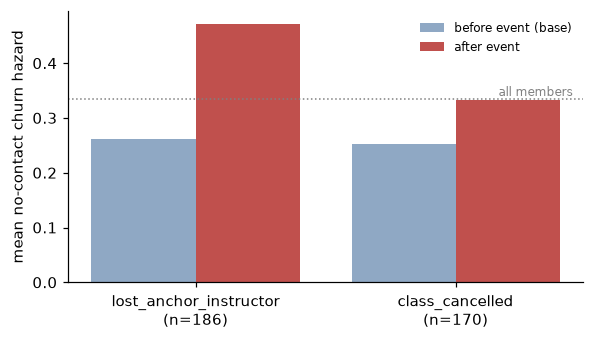

In [3]:
fig, ax = plt.subplots(figsize=(5.5, 3.2))
x = np.arange(len(signal))
ax.bar(x - 0.2, signal["base_churn"], 0.4, label="before event (base)", color="#8fa8c4")
ax.bar(x + 0.2, signal["event_churn"], 0.4, label="after event", color="#c0504d")
ax.axhline(all_event, ls=":", c="grey", lw=1)
ax.text(1.45, all_event, "all members", va="bottom", ha="right", fontsize=8, color="grey")
ax.set_xticks(x, [f"{s}\n(n={n})" for s, n in zip(signal.index, signal["n_flagged"])])
ax.set_ylabel("mean no-contact churn hazard")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "e7_signal_lift.png")

## 2. Ranking: does the KG add to the churn model?

**Setup.** Test split only (`members.split == "test"`); the churn model was trained on the train split, so its test scores are
out-of-sample. A retention team has a budget of `k` contacts, so what matters is who is at the top of the list.

**Baseline (no KG).** Rank by `churn_prob`.

**With KG.** Add a fixed bonus to `churn_prob` for members with `lost_anchor_instructor` or `class_cancelled`, then rank.
Why this combination:

- It is transparent: a gym manager can read "flagged members count as `b` more at risk".
- It does **not** use the documented event multipliers (1.80 / 1.32) or any scenario truth. Adjusting `churn_prob` by the
  known hazard ratio would be circular: it would hand the ranking the answer it is scored against. The bonus is a single
  number a manager could choose without the simulator.
- Because the bonus is a choice, we show a **sensitivity** over three sizes (0.05, 0.10, 0.20) and a rank-only variant
  (`in-band`): flagged members move ahead of unflagged members *within their risk band* and bands never reorder.

**Scores against truth.** Target is `event_churn` (the true post-event hazard).

- **Spearman** between the ranking score and `event_churn` over all test members.
- **Hazard-weighted precision@k**: the mean `event_churn` of the top `k` members (1.0 = everyone in the list would churn
  without contact). k = 50, 100, 200. An *oracle* ranking by `event_churn` itself is shown as a ceiling.

**Uncertainty.** 1,000 bootstrap resamples of the test members (seeded from `ANCHORAI_SEED`); ranking and scoring are redone
inside each resample, and we report the 95% interval of the **difference** to baseline.

In [4]:
test = m[m["split"] == "test"].copy()
test["flag"] = test["lost_anchor_instructor"] | test["class_cancelled"]
BONUSES = (0.05, 0.10, 0.20)
KS = (50, 100, 200)
print(f"{len(test)} test members, {int(test['flag'].sum())} KG-flagged "
      f"({int(test['lost_anchor_instructor'].sum())} lost instructor, {int(test['class_cancelled'].sum())} cancelled class)")

band_rank = test["risk_band"].map({"high": 2, "medium": 1, "low": 0})
rankers = {"baseline (churn_prob)": test["churn_prob"].to_numpy()}
for b in BONUSES:
    rankers[f"KG bonus +{b:.2f}"] = (test["churn_prob"] + b * test["flag"]).to_numpy()
# In-band: band first, then flag, then churn_prob (encoded as one sortable number).
rankers["KG in-band"] = (band_rank * 4 + test["flag"] * 2 + test["churn_prob"]).to_numpy()
rankers["oracle (event_churn)"] = test["event_churn"].to_numpy()
y = test["event_churn"].to_numpy()


def spearman(score, y):
    return pd.Series(score).rank().corr(pd.Series(y).rank())


def prec_at(score, y, k):
    # Stable tie-break on position, so equal scores don't depend on library internals.
    top = np.argsort(-score, kind="stable")[:k]
    return y[top].mean()


def metrics(score, y):
    return {"spearman": spearman(score, y), **{f"p@{k}": prec_at(score, y, k) for k in KS}}


point = pd.DataFrame({name: metrics(s, y) for name, s in rankers.items()}).T
point.round(4)

800 test members, 66 KG-flagged (37 lost instructor, 29 cancelled class)


,spearman,p@50,p@100,p@200
baseline (churn_prob),0.8324,0.7595,0.7089,0.6247
KG bonus +0.05,0.8375,0.7607,0.7134,0.6259
KG bonus +0.10,0.8337,0.7607,0.7134,0.6259
KG bonus +0.20,0.8312,0.7573,0.7154,0.6269
KG in-band,0.8291,0.7481,0.7122,0.6276
oracle (event_churn),1.0000,0.8260,0.7744,0.6763


In [5]:
rng = np.random.default_rng(SEED)
B = 1000
names = list(rankers)
boot = {n: [] for n in names}
for _ in range(B):
    idx = rng.integers(0, len(test), len(test))
    for n in names:
        boot[n].append(metrics(rankers[n][idx], y[idx]))
boot = {n: pd.DataFrame(v) for n, v in boot.items()}

rows = []
for n in names:
    row = {"ranking": n, **{c: point.loc[n, c] for c in point.columns}}
    if n != names[0]:
        for c in point.columns:
            d = boot[n][c] - boot[names[0]][c]
            row[f"{c}_diff"] = point.loc[n, c] - point.loc[names[0], c]
            row[f"{c}_lo"], row[f"{c}_hi"] = d.quantile([0.025, 0.975])
    rows.append(row)
ranking = pd.DataFrame(rows).set_index("ranking")
ranking.round(4).to_csv(RES / "e7_ranking.csv")
ranking.filter(regex="diff|lo|hi").dropna().round(4)

,spearman_diff,spearman_lo,spearman_hi,p@50_diff,p@50_lo,p@50_hi,p@100_diff,p@100_lo,p@100_hi,p@200_diff,p@200_lo,p@200_hi
ranking,,,,,,,,,,,,
KG bonus +0.05,0.0051,-0.0077,0.0188,0.0012,-0.0182,0.0277,0.0045,-0.0039,0.0145,0.0012,-0.0011,0.0028
KG bonus +0.10,0.0013,-0.0127,0.0161,0.0012,-0.0182,0.0277,0.0045,-0.0039,0.0145,0.0012,-0.0011,0.0034
KG bonus +0.20,-0.0011,-0.0160,0.0147,-0.0023,-0.0195,0.0271,0.0065,-0.0038,0.0154,0.0022,-0.0010,0.0056
KG in-band,-0.0033,-0.0190,0.0127,-0.0115,-0.0325,0.0196,0.0032,-0.0080,0.0142,0.0028,-0.0014,0.0048
oracle (event_churn),0.1676,0.1477,0.1931,0.0665,0.0451,0.0974,0.0655,0.0470,0.0870,0.0516,0.0417,0.0636


**Look for:** a difference whose 95% interval excludes 0 (both `_lo` and `_hi` on the same side). Compare the three
bonus sizes and `KG in-band`: if only one setting helps, the result depends on a tuned knob and should be reported that way.
The oracle row bounds what any ranking could reach. Only about 8% of test members are flagged, so most of the top `k` is
unaffected by any bonus and the differences are small; judge them by the intervals, not the point estimates.

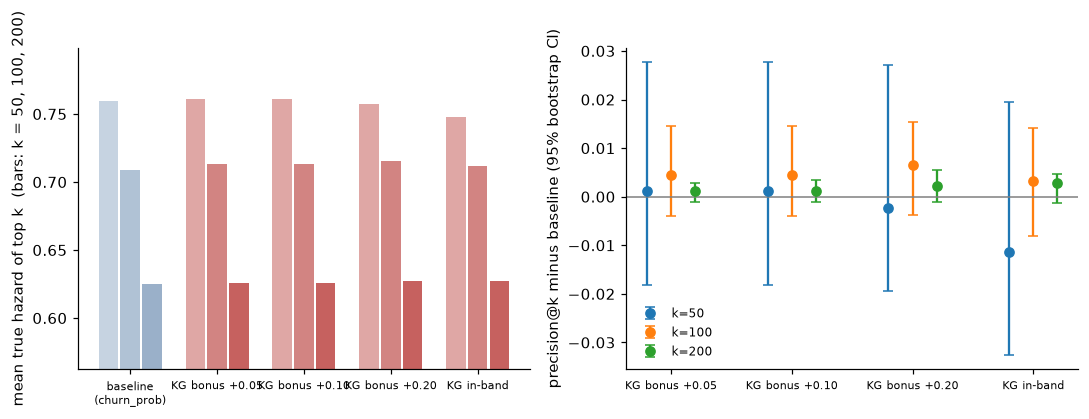

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ordered = [n for n in names if not n.startswith("oracle")]
colors = ["#8fa8c4"] + ["#c0504d"] * (len(ordered) - 1)

ax = axes[0]
for i, k in enumerate(KS):
    col = f"p@{k}"
    vals = ranking.loc[ordered, col]
    ax.bar(np.arange(len(ordered)) * 4 + i, vals, 0.9, color=colors, alpha=0.5 + 0.2 * i)
ax.set_xticks(np.arange(len(ordered)) * 4 + 1, [n.replace(" (", "\n(") for n in ordered], fontsize=7)
ax.set_ylabel("mean true hazard of top k  (bars: k = 50, 100, 200)")
ax.set_ylim(ranking.loc[ordered, [f"p@{k}" for k in KS]].min().min() * 0.9, None)

ax = axes[1]
diff = ranking.loc[ordered[1:]]
for i, k in enumerate(KS):
    col = f"p@{k}"
    ax.errorbar(np.arange(len(diff)) + (i - 1) * 0.2, diff[f"{col}_diff"],
                yerr=[diff[f"{col}_diff"] - diff[f"{col}_lo"], diff[f"{col}_hi"] - diff[f"{col}_diff"]],
                fmt="o", capsize=3, label=f"k={k}")
ax.axhline(0, c="grey", lw=1)
ax.set_xticks(np.arange(len(diff)), [n.replace(" (", "\n(") for n in diff.index], fontsize=7)
ax.set_ylabel("precision@k minus baseline (95% bootstrap CI)")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "e7_ranking.png")

## 3. Rule-level value: with versus without the KG facts

Run the shipped rule base over **all** members twice. Facts are built exactly as the API builds them
(`build_facts`), once with the cached KG facts and once with `kg=None`, in which case the KG facts are simply missing and
rules on them cannot match (D07 `lost_anchor_instructor`, D08 `class_cancelled`, and whatever playbooks use the
`routine_disrupted` fact they assert).

This is the rule layer only: which members get an allowed offer. Part 4 prices the extra offers under the weekly budget,
staff minutes and inventory. Here, as a planner-free measure, we report the
**event-driven excess hazard** `event_churn − base_churn` of members reached only because of the KG: the churn the events
added to them, which is what a timely offer could at most address.

In [7]:
interventions = tables["interventions"]
facts_with = build_facts(scores, features, interventions, kg)
facts_without = build_facts(scores, features, interventions, None)
out_with = {mid: run(rules, f, mid) for mid, f in facts_with.items()}
out_without = {mid: run(rules, f, mid) for mid, f in facts_without.items()}

per = pd.DataFrame({
    "offers_with": {k: tuple(p.offer_id for p in o.allowed) for k, o in out_with.items()},
    "offers_without": {k: tuple(p.offer_id for p in o.allowed) for k, o in out_without.items()},
    "rules_with": {k: {f.rule_id for f in o.firings} for k, o in out_with.items()},
    "rules_without": {k: {f.rule_id for f in o.firings} for k, o in out_without.items()},
})
per["n_with"] = per["offers_with"].map(len)
per["n_without"] = per["offers_without"].map(len)
per["gains"] = (per["n_with"] > 0) & (per["n_without"] == 0)
per["loses"] = (per["n_with"] == 0) & (per["n_without"] > 0)
per["new_offers"] = [sorted(set(a) - set(b)) for a, b in zip(per["offers_with"], per["offers_without"])]
per["dropped_offers"] = [sorted(set(b) - set(a)) for a, b in zip(per["offers_with"], per["offers_without"])]
per["changed"] = per["offers_with"] != per["offers_without"]
per["new_rules"] = [sorted(a - b) for a, b in zip(per["rules_with"], per["rules_without"])]
per = per.join(truth[["base_churn", "event_churn"]])
per["excess"] = per["event_churn"] - per["base_churn"]

summary = pd.Series({
    "members": len(per),
    "with an allowed offer, with KG": int((per["n_with"] > 0).sum()),
    "with an allowed offer, without KG": int((per["n_without"] > 0).sum()),
    "gain an allowed offer (none -> some)": int(per["gains"].sum()),
    "lose all allowed offers (some -> none)": int(per["loses"].sum()),
    "offer list changes at all": int(per["changed"].sum()),
    "members reached only with KG: sum excess hazard": per.loc[per["gains"], "excess"].sum(),
    "members reached only with KG: mean excess hazard": per.loc[per["gains"], "excess"].mean(),
    "members whose list changes: sum excess hazard": per.loc[per["changed"], "excess"].sum(),
    "all members: sum excess hazard": per["excess"].sum(),
})
summary.round(3).to_frame("value")

,value
members,4000.000
"with an allowed offer, with KG",1227.000
"with an allowed offer, without KG",984.000
gain an allowed offer (none -> some),243.000
lose all allowed offers (some -> none),0.000
offer list changes at all,298.000
members reached only with KG: sum excess hazard,34.505
members reached only with KG: mean excess hazard,0.142
members whose list changes: sum excess hazard,43.696
all members: sum excess hazard,60.425


In [8]:
changed = per[per["changed"]]
by_rule = (
    changed.explode("new_rules").dropna(subset=["new_rules"]).groupby("new_rules")
    .agg(members=("excess", "size"), gain_offer=("gains", "sum"), sum_excess=("excess", "sum"))
)
by_offer = pd.Series([o for offers in changed["new_offers"] for o in offers]).value_counts().rename("members_newly_offered")
dropped = pd.Series([o for offers in changed["dropped_offers"] for o in offers]).value_counts().rename("members_no_longer_offered")

table = by_rule.assign(kind="rule firing only with KG").rename_axis("item").reset_index()
table = pd.concat([
    pd.DataFrame({"item": summary.index, "value": summary.values, "kind": "summary"}),
    table.rename(columns={"members": "value"})[["item", "value", "kind", "gain_offer", "sum_excess"]],
    by_offer.rename_axis("item").reset_index().rename(columns={"members_newly_offered": "value"}).assign(kind="offer newly allowed"),
    dropped.rename_axis("item").reset_index().rename(columns={"members_no_longer_offered": "value"}).assign(kind="offer no longer allowed"),
], ignore_index=True)
table.round(3).to_csv(RES / "e7_rules_with_without_kg.csv", index=False)
print("rules that fire only because of the KG facts:")
display(by_rule.round(3))
print("offers newly allowed:", by_offer.to_dict(), "| no longer allowed:", dropped.to_dict())

rules that fire only because of the KG facts:


,members,gain_offer,sum_excess
new_rules,,,
D07_lost_instructor,159,132,33.023
D08_class_cancelled,139,111,10.673
P03_disrupted_checkin,263,216,38.367
P03b_disrupted_checkin_email,35,27,5.329


offers newly allowed: {'checkin_message': 279} | no longer allowed: {}


**Look for:** (a) which rules appear in `new_rules` besides D07/D08 (the playbooks fed by `routine_disrupted`);
(b) members who *lose* an offer with the KG: that means a KG fact turned on a guardrail or changed priorities, so check it
is intended; (c) how many KG-flagged members are already reached without the KG (the churn model already puts them
in a high band), since those add nothing at the rule layer.

In [9]:
flagged = per.join(m[["lost_anchor_instructor", "class_cancelled", "risk_band"]]).query("lost_anchor_instructor or class_cancelled")
pd.crosstab(flagged["risk_band"], flagged["gains"].map({True: "reached only with KG", False: "not newly reached"}), margins=True)

gains,not newly reached,reached only with KG,All
risk_band,,,
high,66,0,66
low,36,243,279
medium,11,0,11
All,113,243,356


## 4. Plan value: with versus without the KG facts

Part 3 says who *can* be offered something. Here B's planners choose who *is* contacted under the week's limits, from the
two candidate sets of part 3 (`out_with`, `out_without`), with everything else as the app does it:

- **Candidates:** `build_options` (B) on each outcome's allowed offers, live catalogue, valued by the planner's CBR uplift estimate.
- **Planners:** `greedy-uplift`, `exact` (CP-SAT, linear objective) and the `ga` (3 seeds), at the default $1,500 budget with
  36 h (the seeded roster; staff time binds) and 120 h of staff time (HANDOFFS #31).
- **Score:** B's evaluator, `evaluate(plan, load_truth())["extra_retained"]`: the scenario's **true** uplift over the plan.
  We also count how many contacts in each with-KG plan go to members who are reachable **only** because of the KG (part 3's `gains`).

The planner sees the KG only through the candidates: if CBR cannot tell members apart for the check-in (B's E3), it has no
reason to prefer the KG-reached members, so this measures what the KG's extra candidates are worth to *this* planner.
About 2 minutes.

In [10]:
from sqlmodel import Session

from anchorai import catalog
from anchorai.cbr.reasoner import uplift_series
from anchorai.db.session import get_engine
from anchorai.optimisation.baselines import greedy_uplift
from anchorai.optimisation.contacts import app_case_base
from anchorai.optimisation.evaluate import evaluate, load_truth
from anchorai.optimisation.exact import solve_linear
from anchorai.optimisation.ga import ga, load_cohorts
from anchorai.optimisation.model import build_options, limits_for
from anchorai.optimisation.model import violations as broken_limits

with Session(get_engine()) as session:
    live_offers = catalog.list_offers(session, active_only=True)
    staff = catalog.list_staff(session)
    uplift = uplift_series(app_case_base(session))
    cohorts = load_cohorts(session)
plan_truth = load_truth(tables)
candidates = {"with KG": build_options(out_with, live_offers, scores, uplift),
              "without KG": build_options(out_without, live_offers, scores, uplift)}
kg_only = set(per.index[per["gains"]])
PLANNERS = {
    "greedy-uplift": lambda o, lim, seed: greedy_uplift(o, lim),
    "exact": lambda o, lim, seed: solve_linear(o, lim)[0],
    "ga": lambda o, lim, seed: ga(o, lim, seed, cohorts=cohorts),
}

rows = []
for hours in (36, 120):
    limits = limits_for(1500, hours * 60, live_offers, staff)
    for planner, select in PLANNERS.items():
        for seed in range(3) if planner == "ga" else [0]:
            for name, opts in candidates.items():
                plan = select(opts, limits, seed)
                assert not broken_limits(plan, opts, limits)
                score = evaluate(plan, plan_truth)
                rows.append({"staff_hours": hours, "planner": planner, "seed": seed, "plan": name,
                             "contacts": score["contacts"], "extra_retained": score["extra_retained"],
                             "estimated_extra": score["estimated_extra"],
                             "kg_only_contacts": int(plan["member_id"].isin(kg_only).sum()),
                             "kg_only_extra": evaluate(plan[plan["member_id"].isin(kg_only)], plan_truth)["extra_retained"]})
kg_runs = pd.DataFrame(rows)
kg_value = kg_runs.pivot_table(index=["staff_hours", "planner"], columns="plan", values="extra_retained", aggfunc="mean")
kg_value["gain (with - without)"] = kg_value["with KG"] - kg_value["without KG"]
reach = kg_runs[kg_runs["plan"] == "with KG"].groupby(["staff_hours", "planner"])[["contacts", "kg_only_contacts", "kg_only_extra"]].mean()
kg_plan = kg_value.join(reach)
kg_plan.round(3).to_csv(RES / "e7_plan_value.csv")
kg_plan.round(2)

with KG  without KG  gain (with - without)  \
staff_hours planner                                                     
36          exact            17.47       17.61                  -0.13   
            ga               18.96       19.34                  -0.38   
            greedy-uplift    19.35       19.62                  -0.26   
120         exact            48.82       41.84                   6.98   
            ga               48.81       41.63                   7.18   
            greedy-uplift    50.06       43.09                   6.97   

                           contacts  kg_only_contacts  kg_only_extra  
staff_hours planner                                                   
36          exact             182.0              21.0           0.41  
            ga                182.0              15.0           0.40  
            greedy-uplift     182.0              10.0           0.29  
120         exact             832.0             243.0           5.03  
            ga                829.0             243.0           5.03  
            greedy-uplift     864.0             243.0           5.03

**Look for:** the gain column against its size relative to the plan (about 12-60 extra members); how many KG-only members
the with-KG plans actually contact (`kg_only_contacts`) and what the true uplift on those contacts is (`kg_only_extra`). If
the planner rarely picks them, the KG's reach (part 3) does not turn into plan value with this uplift estimate; say so.

## Findings

From the run on 2026-10-20 (seed 42, the data build after A's 2026-10-17 changes, the rule base after the C1–C5 review
fixes). Parts 1-3 are unchanged from 2026-10-17; part 4 is new, with Stream B's planners and evaluator.

- **Signal.** The KG flags pick out the members the scenario's events hurt. Within-member lift (hazard after the event / before) is
  1.80 for a lost instructor (186 members) and 1.32 for a cancelled class (170), matching A's `a5_event_lift.csv` exactly.
  Raw lift against all members is lower (1.41 and 1.00) because class-goers are lower-risk to begin with, so "flagged
  members churn more than everyone else" understates the effect.
- **Ranking: no detectable gain.** On the 800 test members (66 flagged), ranking by `churn_prob` alone has Spearman 0.832
  against the true post-event hazard. Adding a KG bonus changes it by +0.005 [95% CI −0.008, +0.019] (+0.05), +0.001
  [−0.013, +0.016] (+0.10) and −0.001 [−0.016, +0.015] (+0.20); ranking flagged members first within their band gives
  −0.003 [−0.019, +0.013]. Hazard-weighted precision@50/100/200 moves by at most ±0.012, every interval includes 0, and the
  result does not depend on the bonus size. The oracle (ranking by the truth) is +0.168, so there is room the KG doesn't
  fill: only 8% of members are flagged, and the churn model already explains most of the hazard.
- **Rule layer: this is where the KG adds information.** With the KG facts, 243 more members get an allowed offer (984 →
  1,227) and none lose one. All 243 are low-risk by the model; the KG reaches them through D07/D08 → P03 (or P03b without
  a phone), and the only offer added is the free `checkin_message` (279 members), which G04 allows for low-risk members.
  Those 243 hold 34.5 of the 60.4 total event-driven excess hazard (57%; mean +0.14 each). Flagged high- and medium-risk
  members are reached with or without the KG.
- **Plan value: it depends on staff time.** B's planners choosing from the two candidate sets at the default $1,500,
  scored on the true uplift (extra members retained):

  | staff time | with KG | without KG | gain | KG-only members contacted | their true uplift |
  |---|---|---|---|---|---|
  | 36 h | 17.5-19.4 | 17.6-19.6 | −0.1 to −0.4 | 10-21 of 243 | 0.3-0.4 |
  | 120 h | 48.8-50.1 | 41.6-43.1 | +7.0 to +7.2 (+17%) | 243 of 243 | 5.0 |

  At the seeded 36 h the plan is full with 182 contacts, and the planner's CBR estimates give the KG-only check-ins no
  reason to beat the contacts it already has (B's E3: CBR cannot tell members apart for the check-in), so the KG adds
  nothing and costs a fraction of a member. With 120 h every KG-only member is contacted; they account for 5.0 of the
  7.0-7.2 gain, the rest coming from the 55 other members whose offer list the KG facts change. So the KG's reach turns into
  plan value only when there is staff time to spare; at the seeded roster it is a list of extra candidates, not extra
  retention.
- **Limits.** The events and their effect sizes are synthetic (`docs/SCENARIO.md`), and the churn model is blind to
  events by construction, so the rule-layer gain is a recovery test of a known effect, not evidence from real churn. The
  per-rule counts are among the 298 members whose offer list changes, so D07 shows 159 of its 186. Part 4 builds facts
  without the app's logged contacts (as parts 1-3 do), so its plans are not the app's next-week plan; E6 part 4 has that.
- **Verdict for the report.** The KG doesn't improve *who ranks highest*, but it changes *who gets contacted*: it surfaces
  low-risk members whose routine was just disrupted, a group the churn score misses, and routes them to a free check-in.
  The cost is 279 extra check-ins, none of them paid offers. Those check-ins are worth about 7 extra members when staff
  time allows (120 h), and nothing at the seeded 36 h, where the planner prefers the contacts it already has.
